Let's implement an INS (Inertial Navigation System) that fuses IMU + GNSS using an EKF. The main difference with the previous EKFs is that we have two different measurements coming into our EKF:
- IMU: high frequency (100Hz up to 400Hz)
- GNSS: low frequency (1Hz to 10 Hz)

The prediction step is driven by the IMU. The idea is to integrate non-linear accelerations and angular rates into position, velocity and orientation.
The update step is driven by GNSS. IMU integration accumulates drift, so GNSS acts as a boundary anchor.

$$\mathbf{x} = \begin{bmatrix} p_x & p_y & v_x & v_y & \psi & b_{ax} & b_{ay} & b_g \end{bmatrix}^T$$
- $(p_x, p_y)$: Position in the global/world frame.
- $(v_x, v_y)$: Velocity in the global/world frame.
- $\psi$: Heading angle (yaw) relative to the global X-axis.
- $(b_{ax}, b_{ay})$: Accelerometer biases in the body frame.
- $b_g$: Gyroscope bias.

#### IMU Measurements (Control Inputs)
$$\mathbf{u}_k = \begin{bmatrix} a_m^x & a_m^y & \omega_m \end{bmatrix}^T$$
- $(a_m^x, a_m^y)$: Raw accelerations measured by the IMU in its local body frame.
- $\omega_m$: Raw angular velocity measured by the gyroscope.

#### Continuous time kinematics

The EKF maintains positions in world coordinates, so we need to transform body-frame accelerations into world-frame accelerations. We will use the 2D rotation matrix:
$$R(\psi) = \begin{bmatrix} \cos\psi & -\sin\psi \\ \sin\psi & \cos\psi \end{bmatrix}$$

To rotate a point to world frame (although in our case we will be rotating accelerations):
$\begin{bmatrix} x' \\ y'\end{bmatrix} = R(\psi) \begin{bmatrix}x \\ y\end{bmatrix}$

The continuous differential equations $\dot{\mathbf{x}} = f(\mathbf{x}, \mathbf{u})$ governing system motion are:

$$\begin{aligned} 
\dot{p}_x &= v_x \\ 
\dot{p}_y &= v_y \\ 
\begin{bmatrix} 
    \dot{v}_x \\ 
    \dot{v}_y 
\end{bmatrix} &= 
    R(\psi) \begin{bmatrix} a_m^x - b_{ax} \\ a_m^y - b_{ay} \end{bmatrix} = 
    \begin{bmatrix} (a_m^x - b_{ax})\cos\psi - (a_m^y - b_{ay})\sin\psi \\ 
    (a_m^x - b_{ax})\sin\psi + (a_m^y - b_{ay})\cos\psi \end{bmatrix} \\ 
\dot{\psi} &= \omega_m - b_g \\ 
\dot{b}_{ax} &= 0, \quad \dot{b}_{ay} = 0, \quad \dot{b}_g = 0 \end{aligned}$$

##### State extrapolation

For an IMU sample arriving over sampling interval $\Delta t$, propagate the nominal state $\mathbf{x}_k$ using discrete numerical integration:

$$\begin{aligned} \psi_k &= \psi_{k-1} + (\omega_{m,k} - b_{g, k-1}) \Delta t \\ \mathbf{a}_k^{\text{world}} &= R(\psi_{k-1}) \begin{bmatrix} a_{m,k}^x - b_{ax, k-1} \\ a_{m,k}^y - b_{ay, k-1} \end{bmatrix} \\ \begin{bmatrix} v_{x, k} \\ v_{y, k} \end{bmatrix} &= \begin{bmatrix} v_{x, k-1} \\ v_{y, k-1} \end{bmatrix} + \mathbf{a}_k^{\text{world}} \Delta t \\ \begin{bmatrix} p_{x, k} \\ p_{y, k} \end{bmatrix} &= \begin{bmatrix} p_{x, k-1} \\ p_{y, k-1} \end{bmatrix} + \begin{bmatrix} v_{x, k-1} \\ v_{y, k-1} \end{bmatrix} \Delta t + \frac{1}{2} \mathbf{a}_k^{\text{world}} \Delta t^2 \\ \mathbf{b}_{a, k} &= \mathbf{b}_{a, k-1} \\ b_{g, k} &= b_{g, k-1} \end{aligned}$$

In an IMU-driven filter, the physics are defined as continuous differential equations ($\dot{\mathbf{x}} = f(\mathbf{x}, \mathbf{u})$). 
Because sensor measurements arrive as discrete samples at interval $\Delta t$, we cannot compute an exact continuous integral $\int f(\mathbf{x}, \mathbf{u}) dt$. Instead, we must numerically approximate the integral over each discrete step.The set of equations in that step uses two standard numerical integration methods:
- **Forward Euler Integration (1st-Order)**:

Used for heading, velocity, and biases:$$\mathbf{x}_k = \mathbf{x}_{k-1} + f(\mathbf{x}_{k-1}, \mathbf{u}_k) \Delta t$$This assumes rates of change (angular velocity and acceleration) remain constant over the tiny interval $\Delta t$.
- **Second-Order Kinematic / Taylor Expansion Integration**:

Used for position:$$\mathbf{p}_k = \mathbf{p}_{k-1} + \mathbf{v}_{k-1} \Delta t + \frac{1}{2} \mathbf{a}_k^{\text{world}} \Delta t^2$$This accounts for constant acceleration over the interval $\Delta t$, providing higher fidelity than basic Euler integration for position.

Taylor expansion integration evaluates the continuous state function $\mathbf{x}(t)$ and its time derivatives at time $t_{k-1}$, expanding them in a power series of the time step $\Delta t$:$$\mathbf{x}_k = \mathbf{x}(t_{k-1} + \Delta t) = \mathbf{x}_{k-1} + \left.\frac{d\mathbf{x}}{dt}\right\vert{}_{k-1} \Delta t + \frac{1}{2!} \left.\frac{d^2\mathbf{x}}{dt^2}\right\vert{}_{k-1} \Delta t^2 + \frac{1}{3!} \left.\frac{d^3\mathbf{x}}{dt^3}\right\vert{}_{k-1} \Delta t^3 + \dots$$

For position, where $\dot{p}= v$ and $\ddot{p} = \dot{v} = a^{world}$. Applying the expansion up to $\Delta t^2$:
$$\mathbf{p}_k = \mathbf{p}_{k-1} + \left.\dot{\mathbf{p}}\right\vert{}_{k-1} \Delta t + \frac{1}{2} \left.\ddot{\mathbf{p}}\right\vert{}_{k-1} \Delta t^2
= \mathbf{p}_{k-1} + \mathbf{v}_{k-1} \Delta t + \frac{1}{2} \mathbf{a}_{k-1}^w \Delta t^2
$$

**Why Numerical Integration is Essential Here**: In standard target tracking (like a CV radar model), the discrete transition matrix $F$ directly propagates the state ($\hat{\mathbf{x}}_k = F \hat{\mathbf{x}}_{k-1}$) because the motion model is assumed linear.
In IMU fusion, because the state update depends on continuous non-linear inputs ($\mathbf{u}_k = [a_m^x, a_m^y, \omega_m]^T$ rotated by heading $\psi$), we must pass the high-rate IMU readings through a discrete numerical integration routine to predict the mean state $\hat{\mathbf{x}}_k$

##### Computing $F$ for covariance propagation

We need to discretize the transition function. We have two ways, continuous-first linearization or discretize-first (numerical integration of $f(\bold{x}, \bold{u}$). We will choose the first one:
1. Write continuous physics equations: $\dot{\mathbf{x}} = f(\mathbf{x}, \mathbf{u})$
2. Calculate the continuous system Jacobian: $A = \frac{\partial f}{\partial \mathbf{x}}$
3. Discretize the Jacobian using first-order Taylor expansion: $F_k \approx I + A \Delta t$

$$A = \begin{bmatrix} \frac{\partial f_1}{\partial p_x} & \frac{\partial f_1}{\partial p_y} & \frac{\partial f_1}{\partial v_x} & \frac{\partial f_1}{\partial v_y} & \frac{\partial f_1}{\partial \psi} & \frac{\partial f_1}{\partial b_{ax}} & \frac{\partial f_1}{\partial b_{ay}} & \frac{\partial f_1}{\partial b_g} \\ \frac{\partial f_2}{\partial p_x} & \frac{\partial f_2}{\partial p_y} & \frac{\partial f_2}{\partial v_x} & \frac{\partial f_2}{\partial v_y} & \frac{\partial f_2}{\partial \psi} & \frac{\partial f_2}{\partial b_{ax}} & \frac{\partial f_2}{\partial b_{ay}} & \frac{\partial f_2}{\partial b_g} \\ \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots \\ \frac{\partial f_8}{\partial p_x} & \frac{\partial f_8}{\partial p_y} & \frac{\partial f_8}{\partial v_x} & \frac{\partial f_8}{\partial v_y} & \frac{\partial f_8}{\partial \psi} & \frac{\partial f_8}{\partial b_{ax}} & \frac{\partial f_8}{\partial b_{ay}} & \frac{\partial f_8}{\partial b_g} \end{bmatrix} = \begin{bmatrix} 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & -\dot{v}_y & -\cos\psi & \sin\psi & 0 \\ 0 & 0 & 0 & 0 & \dot{v}_x & -\sin\psi & -\cos\psi & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & -1 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \end{bmatrix}$$

$$F_k \approx I + A \Delta t = \begin{bmatrix} 1 & 0 & \Delta t & 0 & 0 & 0 & 0 & 0 \\ 0 & 1 & 0 & \Delta t & 0 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 & -\dot{v}_y \Delta t & -\cos\psi \Delta t & \sin\psi \Delta t & 0 \\ 0 & 0 & 0 & 1 & \dot{v}_x \Delta t & -\sin\psi \Delta t & -\cos\psi \Delta t & 0 \\ 0 & 0 & 0 & 0 & 1 & 0 & 0 & -\Delta t \\ 0 & 0 & 0 & 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1 \end{bmatrix}$$

#### Measurement vector and $H$

$$z_k = \begin{bmatrix} p_x^{\text{gnss}} \\ p_y^{\text{gnss}} \\ v_x^{\text{gnss}} \\ v_y^{\text{gnss}} \end{bmatrix}$$

GNSS directly measures the first positions of the state vector $(p_x, p_y, v_x, v_y)$, so $h(x)$ is linear:
$$H = \begin{bmatrix} 1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 1 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 1 & 0 & 0 & 0 & 0 \end{bmatrix}$$

#### Process Noise $Q$
In the previous EKF examples I implemented, process noise was used to model aircraft maneuvers or external influences on the aircraft that might not be captured by the dynamics model. Now, process noise models imperfections in the IMU sensor hardware, which comes from:
- **Sensor Measurement Noise**: White noise density in raw accelerometer and gyro outputs ($\sigma_{a_x}, \sigma_{a_y} \sigma_{\omega}$).
- **Bias Instability**: Random walk noise driving bias drift over time ($\sigma_{b_a}, \sigma_{b_g}$)

$$Q_k = \begin{bmatrix} 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & \sigma_a^2 \Delta t & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & \sigma_a^2 \Delta t & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & \sigma_\omega^2 \Delta t & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & \sigma_{b_a}^2 \Delta t & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & \sigma_{b_a}^2 \Delta t & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & \sigma_{b_g}^2 \Delta t \end{bmatrix}$$

In [13]:
import numpy as np
import matplotlib.pyplot as plt

In [14]:
px0 = 0
py0 = 0
vx0 = 0
vy0 = 0
psi0 = 0
bax0 = 0
bay0 = 0
bg0 = 0

sigma_p = 3
sigma_px = sigma_p
sigma_py = sigma_p
sigma_v = 0.3
sigma_vx = sigma_v
sigma_vy = sigma_v

sigma_a = 0.2
sigma_w = 0.01
sigma_ba = 1e-4
sigma_bg = 1e-5

dt = 0.01

In [20]:
def _integrate_kinematics(x, z, dt):
    """Non linear state propagation.
    Directly integrate physics equations to update the state mean x
    """
    px, py, vx, vy, psi, b_ax, b_ay, b_g = x

    # correct imu measurements
    ax_b = z[0] - b_ax
    ay_b = z[1] - b_ay
    w_b = z[2] - b_g

    # rotate acceleration to world frame
    ax_w = ax_b * np.cos(psi) - ay_b * np.sin(psi)
    ay_w = ax_b * np.sin(psi) + ay_b * np.cos(psi)

    # propagate mean
    return np.array([
        px + vx * dt + .5 * ax_w * dt**2,
        py + vy * dt + .5 * ay_w * dt**2,
        vx + ax_w * dt,
        vy + ay_w * dt,
        psi + w_b * dt,
        b_ax, b_ay, b_g
    ]), ax_w, ay_w

class EKF:
    def __init__(self):
        self.x = np.array([px0, py0, vx0, vy0, psi0, bax0, bay0, bg0])
        self.P = np.diag([sigma_px**2, sigma_py**2, sigma_vx**2, sigma_vy**2, sigma_w**2, sigma_ba**2, sigma_ba**2, sigma_bg**2])
        self.P = np.diag([
            sigma_px**2, sigma_py**2, 
            sigma_vx**2, sigma_vy**2, 
            (0.5)**2,             # Initial heading uncertainty (~30 deg)
            (0.5)**2, (0.5)**2,   # Initial accel bias uncertainty
            (0.05)**2             # Initial gyro bias uncertainty
        ])
        self.Q = np.diag([
            0, 
            0, 
            sigma_a**2 * dt, 
            sigma_a**2 * dt, 
            sigma_w**2 * dt, 
            sigma_ba**2 * dt, 
            sigma_ba**2 * dt, 
            sigma_bg**2 * dt
        ])
        self.H = np.array([
            [1, 0, 0, 0, 0, 0, 0, 0],
            [0, 1, 0, 0, 0, 0, 0, 0],
            [0, 0, 1, 0, 0, 0, 0, 0],
            [0, 0, 0, 1, 0, 0, 0, 0]
        ])
        self.R = np.diag([sigma_px**2, sigma_py**2, sigma_vx**2, sigma_vy**2])

    def predict(self, z: np.ndarray):
        """z: ndarray. IMU measurement [a_x, a_y, w]"""
        px, py, vx, vy, psi, b_ax, b_ay, b_g = self.x
        
        self.x, ax_w, ay_w = _integrate_kinematics(self.x, z, dt)
        
        F = np.array([
            [1, 0, dt, 0, 0, 0, 0, 0],
            [0, 1, 0, dt, 0, 0, 0, 0],
            [0, 0, 1, 0, -ay_w * dt, -np.cos(psi) * dt, np.sin(psi) * dt, 0],
            [0, 0, 0, 1, ax_w * dt, -np.sin(psi) * dt, -np.cos(psi) * dt, 0],
            [0, 0, 0, 0, 1, 0, 0, -dt],
            [0, 0, 0, 0, 0, 1, 0, 0],
            [0, 0, 0, 0, 0, 0, 1, 0],
            [0, 0, 0, 0, 0, 0, 0, 1]
        ])
        self.P = F @ self.P @ F.T + self.Q

    def update(self, z: np.ndarray):
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        y = z - self.H @ self.x
        self.x = self.x + K @ y

        I = np.identity(8)
        self.P = (I - K @ self.H) @ self.P @ (I - K @ self.H).T + K @ self.R @ K.T
        return self.x, self.P

To generate synthetic data we will generate a ground truth trajectory and derive velocities, accelerations and heading. We will generate the trajectory for a figure 8.

$
p(\bold{x})
\begin{cases} 
x = R \sin(\omega t) \\ 
y = R \sin(2\omega t)
\end{cases}
$

with $R=10$ and $\omega = 0.1$:
$T = \frac{2\pi}{\omega} = \frac{2\pi}{0.1} = 20\pi \approx 62.83\text{ s} \quad (\text{time to complete figure 8})$

$\bold{v}(t) = \dot{\bold{p}}(t) = \begin{bmatrix} v_x = R\omega \cos(\omega t) \\ v_y = 2R\omega \cos(2\omega t) \end{bmatrix}$

$\bold{a}(t) = \dot{\bold{v}}(t) = \begin{bmatrix} a_x = -\omega^2 R \sin(\omega t) \\ a_y = -4\omega^2 R \sin(2\omega t) \end{bmatrix}$

$\psi(t) = \arctan\left(\frac{v_y(t)}{v_x(t)}\right)$

$
\omega(t) = \dot{\psi}(t) 
= \frac{1}{1 + \left(\frac{v_y(t)}{v_x(t)}\right)^2} \cdot \frac{d}{dt}\left(\frac{v_y(t)}{v_x(t)}\right) 
= \frac{1}{1 + \left(\frac{v_y(t)}{v_x(t)}\right)^2} \cdot \frac{a_y(t) v_x(t) - a_x(t) v_y(t)}{v_x(t)^2}
= \frac{a_y(t) v_x(t) - a_x(t) v_y(t)}{v_x(t)^2 + v_y(t)^2}
$


In [21]:
def generate_synthetic_data(
        duration=60.0,                     # simulation duration (s)
        dt_imu=0.01,                # 100Hz IMU
        dt_gnss=0.1,                # 10Hz gnss  
        outage_bounds=(20.0, 35.0), # gnss outage between 20s and 35s
        seed: int | None =42,
        fig8_R=10,
        fig8_w=0.1
):
    if outage_bounds[0] > duration:
        print("warn: outage bounds start is higher than duration, wont' be applied")

    if seed is not None:
        np.random.seed(seed)

    t = np.arange(0, duration, dt)
    N = len(t)

    # true sensor biases
    b_ax_true = .15
    b_ay_true = -.10
    b_g_true = .02

    # ground truth trajectory
    px_gt = fig8_R * np.sin(fig8_w * t)
    py_gt = fig8_R * np.sin(2 * fig8_w * t)
    vx_gt = fig8_R * fig8_w * np.cos(fig8_w *t)
    vy_gt = 2 * fig8_R * fig8_w * np.cos(2 * fig8_w *t)
    ax_gt = -1 * fig8_w**2 * fig8_R * np.sin(fig8_w * t)
    ay_gt = -1 * 4 * fig8_w**2 * fig8_R * np.sin(2 * fig8_w * t)
    psi_gt = np.arctan2(vy_gt, vx_gt)
    omega_gt = (ay_gt * vx_gt - ax_gt * vy_gt) / (vx_gt**2 + vy_gt**2)

    ax_body = ax_gt * np.cos(psi_gt) + ay_gt * np.sin(psi_gt)
    ay_body = -ax_gt * np.sin(psi_gt) + ay_gt * np.cos(psi_gt)

    ax_obs = ax_body + b_ax_true + np.random.normal(0, sigma_a, N)
    ay_obs = ay_body + b_ay_true + np.random.normal(0, sigma_a, N)
    w_obs = omega_gt + b_g_true + np.random.normal(0, sigma_w, N)
    imu_data = np.vstack([ax_obs, ay_obs, w_obs]).T

    gnss_ratio = dt_gnss / dt_imu
    gnss_measurements = []

    for i in range(N):
        if i % gnss_ratio == 0:
            current_time = t[i]
            is_outage = outage_bounds[0] <= current_time <= outage_bounds[1]

            if not is_outage:
                z = np.array([
                    px_gt[i] + np.random.normal(0, sigma_px),
                    py_gt[i] + np.random.normal(0, sigma_py),
                    vx_gt[i] + np.random.normal(0, sigma_vx),
                    vy_gt[i] + np.random.normal(0, sigma_vy)
                ])
                gnss_measurements.append((i, z))

    gt_states = np.vstack([px_gt, py_gt, vx_gt, vy_gt, psi_gt]).T
    true_biases = np.array([b_ax_true, b_ay_true, b_g_true])

    return t, imu_data, gnss_measurements, gt_states, true_biases

In [22]:
t, imu_data, gnss_measurements, gt_states, true_biases = generate_synthetic_data()

ekf = EKF()

gnss_idx = 0
ekf_states = []
P_history = []

for i in range(len(t)):
    u_k = imu_data[i]
    ekf.predict(u_k)
    
    if gnss_idx < len(gnss_measurements) and gnss_measurements[gnss_idx][0] == i:
        z_k = gnss_measurements[gnss_idx][1]
        x, P = ekf.update(z_k)
        gnss_idx += 1
        
    ekf_states.append(x.copy())
    P_history.append(P.copy())

In [23]:
def plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases):
    """
    t: (N,) array of time timestamps
    gt_states: (N, 5) array of true states [px, py, vx, vy, psi]
    ekf_states: (N, 8) array of estimated states [px, py, vx, vy, psi, bax, bay, bg]
    P_history: (N, 8, 8) array of covariance matrices recorded at each timestep
    gnss_measurements: list of tuples (k_idx, z_array)
    true_biases: array [b_ax_true, b_ay_true, b_g_true]
    """
    ekf_states = np.array(ekf_states)
    P_history = np.array(P_history)
    gt_states = np.array(gt_states)

    # Extract GNSS positions for plotting
    gnss_k = [meas[0] for meas in gnss_measurements]
    gnss_t = t[gnss_k]
    gnss_px = [meas[1][0] for meas in gnss_measurements]
    gnss_py = [meas[1][1] for meas in gnss_measurements]

    # Standard deviations (sqrt of diagonal elements of P)
    sigma_px = np.sqrt(P_history[:, 0, 0])
    sigma_py = np.sqrt(P_history[:, 1, 1])

    # Position Errors
    err_px = gt_states[:, 0] - ekf_states[:, 0]
    err_py = gt_states[:, 1] - ekf_states[:, 1]

    fig = plt.figure(figsize=(15, 12))

    # 2D TRAJECTORY MAP
    ax1 = fig.add_subplot(2, 2, 1)
    ax1.plot(gt_states[:, 0], gt_states[:, 1], 'k--', label='Ground Truth', linewidth=2)
    ax1.scatter(gnss_px, gnss_py, c='red', s=15, alpha=0.5, label='GNSS Updates')
    ax1.plot(ekf_states[:, 0], ekf_states[:, 1], 'b-', label='EKF Estimate', linewidth=1.5)
    ax1.set_title('2D Position Trajectory')
    ax1.set_xlabel('Position X [m]')
    ax1.set_ylabel('Position Y [m]')
    ax1.grid(True)
    ax1.legend()
    ax1.axis('equal')

    # BIAS CONVERGENCE
    ax2 = fig.add_subplot(2, 2, 2)
    ax2.plot(t, ekf_states[:, 5], 'r-', label=r'Est $\hat{b}_{ax}$')
    ax2.axhline(true_biases[0], color='r', linestyle='--', label=r'True $b_{ax}$')
    
    ax2.plot(t, ekf_states[:, 6], 'g-', label=r'Est $\hat{b}_{ay}$')
    ax2.axhline(true_biases[1], color='g', linestyle='--', label=r'True $b_{ay}$')
    
    ax2.plot(t, ekf_states[:, 7], 'b-', label=r'Est $\hat{b}_{g}$')
    ax2.axhline(true_biases[2], color='b', linestyle='--', label=r'True $b_{g}$')
    
    ax2.set_title('IMU Bias Convergence')
    ax2.set_xlabel('Time [s]')
    ax2.set_ylabel('Bias Value [m/s², rad/s]')
    ax2.grid(True)
    ax2.legend()

    # FILTER CONSISTENCY: X ERROR & 3-SIGMA BOUNDS
    ax3 = fig.add_subplot(2, 2, 3)
    ax3.plot(t, err_px, 'b-', label='Error ($p_{x,gt} - \\hat{p}_x$)')
    ax3.plot(t, 3 * sigma_px, 'r--', label=r'+3$\sigma$ Bound')
    ax3.plot(t, -3 * sigma_px, 'r--', label=r'-3$\sigma$ Bound')
    ax3.set_title('Position X Error & 3-Sigma Envelope')
    ax3.set_xlabel('Time [s]')
    ax3.set_ylabel('Error [m]')
    ax3.grid(True)
    ax3.legend()

    # FILTER CONSISTENCY: Y ERROR & 3-SIGMA BOUNDS
    ax4 = fig.add_subplot(2, 2, 4)
    ax4.plot(t, err_py, 'b-', label='Error ($p_{y,gt} - \\hat{p}_y$)')
    ax4.plot(t, 3 * sigma_py, 'r--', label=r'+3$\sigma$ Bound')
    ax4.plot(t, -3 * sigma_py, 'r--', label=r'-3$\sigma$ Bound')
    ax4.set_title('Position Y Error & 3-Sigma Envelope')
    ax4.set_xlabel('Time [s]')
    ax4.set_ylabel('Error [m]')
    ax4.grid(True)
    ax4.legend()

    plt.tight_layout()
    plt.show()

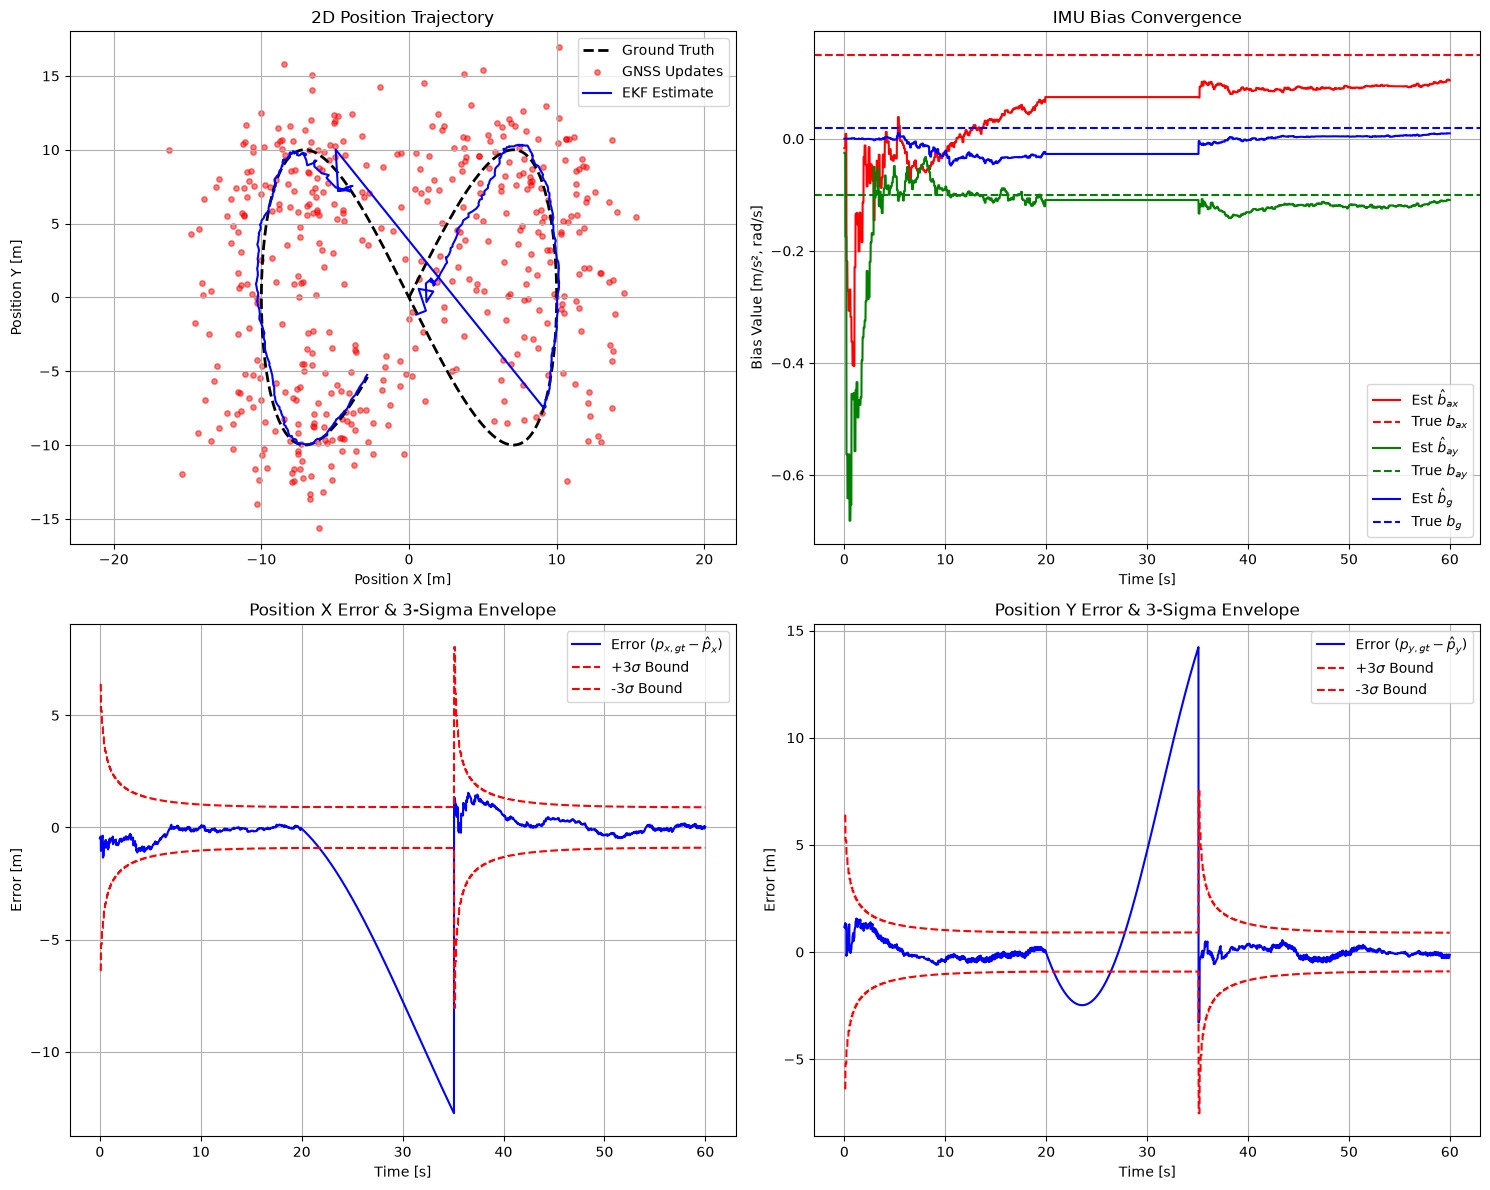

In [24]:
plot_ekf_results(t, gt_states, ekf_states, P_history, gnss_measurements, true_biases)

#### Appendix: Process noise $Q_k$ derivation

The approximation $Q_k \approx G_k Q_c G_k^T \cdot \Delta t$ is the standard mathematical bridge between continuous-time sensor physics and discrete-time Kalman filtering:
##### Physical Intuition of Each Term
- $Q_c$ (Continuous Noise Spectral Density): Sensor datasheets specify noise density, not discrete variance (e.g., accelerometer noise in $\text{m/s}^2/\sqrt{\text{Hz}}$). $Q_c$ represents the rate at which noise energy enters the continuous system per unit time.
- $G_k$ (Noise Projection Matrix): Raw sensor noise originates in the sensor’s local body frame. $G_k$ rotates and maps those physical noise inputs (e.g., body accelerometer and gyro noise) directly into the state rate-of-change vector $\dot{\mathbf{x}}$.
- $G_k Q_c G_k^T$ (State-Space Noise Rate): Transforming $Q_c$ by $G_k$ maps continuous noise power into global state space (e.g., converting body accelerometer noise into global velocity noise rates).
- $\cdot \Delta t$ (Discrete Integration): Variance accumulates linearly over time when integrating independent white noise. Multiplying by $\Delta t$ integrates continuous noise spectral density over the time interval $\Delta t$ to yield discrete variance.

##### Mathematical derivation from continuous white noise
- **Step A: The Continuous Stochastic Differential Equation**. In continuous time, continuous state errors $\delta \mathbf{x}(t)$ driven by zero-mean continuous Gaussian white noise $\mathbf{w}(t)$ follow:$$\delta \dot{\mathbf{x}}(t) = A \delta \mathbf{x}(t) + G_k \mathbf{w}(t)$$where the autocorrelation of continuous white noise is defined using the Dirac delta function $\delta(t - \tau)$:$$E[\mathbf{w}(t) \mathbf{w}^T(\tau)] = Q_c \, \delta(t - \tau)$$

- **Step B: Discrete Integration Over One Time Step**. Integrating this continuous differential equation from $t = 0$ to $t = \Delta t$ yields the discrete-time noise vector $\mathbf{w}_k$ added to the state over that interval:$$\mathbf{w}_k = \int_{0}^{\Delta t} e^{A (\Delta t - \tau)} G_k \mathbf{w}(\tau) \, d\tau$$

- **Step C: First-Order Taylor Approximation** ($e^{A \tau} \approx I$). For high sampling rates ($\Delta t \ll 1$), the state dynamics term $e^{A (\Delta t - \tau)} \approx I$ (the identity matrix). The discrete noise simplifies to:$$\mathbf{w}_k \approx \int_{0}^{\Delta t} G_k \mathbf{w}(\tau) \, d\tau$$

- **Step D: Computing Discrete Covariance** $Q_k = E[\mathbf{w}_k \mathbf{w}_k^T]$. Taking the expectation of the outer product of $\mathbf{w}_k$:
$$Q_k = E\left[ \left( \int_{0}^{\Delta t} G_k \mathbf{w}(\tau) \, d\tau \right) \left( \int_{0}^{\Delta t} G_k \mathbf{w}(s) \, ds \right)^T \right]$$
Pulling the constant matrix $G_k$ and integration outside the expectation operator:
$$Q_k = G_k \left( \int_{0}^{\Delta t} \int_{0}^{\Delta t} E[\mathbf{w}(\tau) \mathbf{w}^T(s)] \, d\tau \, ds \right) G_k^T$$
Substituting $E[\mathbf{w}(\tau) \mathbf{w}^T(s)] = Q_c \, \delta(\tau - s)$:
$$Q_k = G_k \left( \int_{0}^{\Delta t} Q_c \left( \int_{0}^{\Delta t} \delta(\tau - s) \, ds \right) d\tau \right) G_k^T$$
Because $\int \delta(\tau - s) ds = 1$ when the integration range covers $s = \tau$:
$$Q_k = G_k \left( \int_{0}^{\Delta t} Q_c \, d\tau \right) G_k^T = G_k Q_c G_k^T \int_{0}^{\Delta t} d\tau$$
$$Q_k = G_k Q_c G_k^T \cdot \Delta t$$

##### How is G_K obtained ?
The noise projection matrix $G_k$ (often written in continuous time as $G$) is obtained by taking the partial derivative of the continuous system dynamics $f(\mathbf{x}, \mathbf{u}, \mathbf{w})$ with respect to the noise vector $\mathbf{w}$:
$$G = \left. \frac{\partial f(\mathbf{x}, \mathbf{u}, \mathbf{w})}{\partial \mathbf{w}} \right\vert{}_{\mathbf{w} = 0}$$

Just as the state transition Jacobian $A = \frac{\partial f}{\partial \mathbf{x}}$ describes how perturbations in the state affect system rates of change, $G$ describes how physical sensor noise enters and perturbs those same rates of change.

**Explicitly Inject Noise into the Kinematic Equations**. Real IMU sensors include measurement noise ($n_a, n_\omega$) and bias drift noise ($n_{b_a}, n_{b_g}$).Define the continuous noise vector $\mathbf{w}(t)$ with 6 noise sources:
$$\mathbf{w}(t) = \begin{bmatrix} n_{a_x} & n_{a_y} & n_{\omega} & n_{b_{ax}} & n_{b_{ay}} & n_{b_g} \end{bmatrix}^T$$

Rewriting the kinematic differential equations $\dot{\mathbf{x}} = f(\mathbf{x}, \mathbf{u}, \mathbf{w})$ to include these noise terms:
$$\begin{aligned} \dot{p}_x &= v_x \\ \dot{p}_y &= v_y \\ \dot{v}_x &= (a_m^x - b_{ax} - n_{a_x})\cos\psi - (a_m^y - b_{ay} - n_{a_y})\sin\psi \\ \dot{v}_y &= (a_m^x - b_{ax} - n_{a_x})\sin\psi + (a_m^y - b_{ay} - n_{a_y})\cos\psi \\ \dot{\psi} &= \omega_m - b_g - n_\omega \\ \dot{b}_{ax} &= n_{b_{ax}} \\ \dot{b}_{ay} &= n_{b_{ay}} \\ \dot{b}_g &= n_{b_g} \end{aligned}$$

$$G = \begin{bmatrix} 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 \\ -\cos\psi & \sin\psi & 0 & 0 & 0 & 0 \\ -\sin\psi & -\cos\psi & 0 & 0 & 0 & 0 \\ 0 & 0 & -1 & 0 & 0 & 0 \\ 0 & 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 0 & 0 & 1 \end{bmatrix}$$

$$G_k Q_c G_k^T = \begin{bmatrix} 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & \sigma_{a_x}^2 \cos^2\psi + \sigma_{a_y}^2 \sin^2\psi & (\sigma_{a_x}^2 - \sigma_{a_y}^2)\sin\psi\cos\psi & 0 & 0 & 0 & 0 \\ 0 & 0 & (\sigma_{a_x}^2 - \sigma_{a_y}^2)\sin\psi\cos\psi & \sigma_{a_x}^2 \sin^2\psi + \sigma_{a_y}^2 \cos^2\psi & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & \sigma_{\omega}^2 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & \sigma_{b_a}^2 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & \sigma_{b_a}^2 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & \sigma_{b_g}^2 \end{bmatrix}$$

Assuming symmetric accelerometer noise ($\sigma_{a_x} = \sigma_{a_y} = \sigma_a$), the cross terms vanish ($\cos^2\psi + \sin^2\psi = 1$), simplifying $Q_k$ into a clean matrix:$$Q_k = \begin{bmatrix} 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & \sigma_a^2 \Delta t & 0 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & \sigma_a^2 \Delta t & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & \sigma_\omega^2 \Delta t & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & \sigma_{b_a}^2 \Delta t & 0 & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & \sigma_{b_a}^2 \Delta t & 0 \\ 0 & 0 & 0 & 0 & 0 & 0 & 0 & \sigma_{b_g}^2 \Delta t \end{bmatrix}$$